# TFPSSTD New Dataset Colab Pipeline

Purpose:

1. Access IEEE DataPort dataset files through AWS S3.
2. Inspect the new TFPSSTD dataset structure before training.
3. Keep feature extraction, normalization, and feature selection modular.
4. Extract magnitude, phase, and RCS-like features when complex data is available.
5. Compute train-only statistics and apply them to validation/test.
6. Run feature-selection experiments.
7. Train baseline models from scratch on the new dataset.

Important:

- Do not paste AWS keys into chat.
- Do not use Pol-ISARSpaceTarget trained weights directly on TFPSSTD.
- Train from scratch first. Transfer/domain adaptation can be a later separate experiment.


In [1]:
!pip -q install awscli boto3 s3fs h5py scipy pillow scikit-learn matplotlib pandas torchvision


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 65.7/65.7 kB 7.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 104.8/104.8 kB 8.8 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 65.3/65.3 kB 5.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 65.1/65.1 kB 5.7 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.7/59.7 kB 5.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.5/57.5 kB 5.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.6/54.6 kB 3.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.5/54.5 kB 5.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━

In [2]:
import json
import gc
import os
import random
import shutil
import subprocess
import sys
import tarfile
import zipfile
from getpass import getpass
from pathlib import Path
from typing import Dict, List, Sequence, Tuple

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.io as sio
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import SGDClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from torch.utils.data import DataLoader, Dataset
from torchvision.models import resnet18

MAT_IMAGE_KEY = "ISAR_FullPol_DualADMM"
FEATURE_SIZE = 32
CNN_IMAGE_SIZE = 128
BATCH_SIZE = 4

print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


PyTorch: 2.11.0+cu128
CUDA: True
GPU: Tesla T4


In [4]:
import shutil
from pathlib import Path

PROJECT_DIR = Path("/content/polisar_project")
if PROJECT_DIR.exists():
    shutil.rmtree(PROJECT_DIR)

print("Cleared old project extraction.")

Cleared old project extraction.


## Mount Drive and Load Project Modules

Upload/copy one of these ZIP files to Drive:

`/content/drive/MyDrive/drdo/POLISAR_TFPSSTD_COLAB_GUIDE_PACKAGE.zip`

or

`/content/drive/MyDrive/drdo/POLISAR_code_for_DRDO_guide_CLEAN.zip`

The ZIP contains separate files:

- `feature_extraction.py`
- `feature_normalization.py`
- `feature_selection.py`


In [5]:
from google.colab import drive

drive.mount("/content/drive")

PROJECT_ZIP_CANDIDATES = [
    Path("/content/drive/MyDrive/drdo/POLISAR_TFPSSTD_COLAB_GUIDE_PACKAGE.zip"),
    Path("/content/drive/MyDrive/drdo/POLISAR_code_for_DRDO_guide_CLEAN.zip"),
]
PROJECT_ZIP = next((path for path in PROJECT_ZIP_CANDIDATES if path.exists()), PROJECT_ZIP_CANDIDATES[0])
PROJECT_DIR = Path("/content/polisar_project")
PROJECT_DIR.mkdir(parents=True, exist_ok=True)

def unpack_project_zip(zip_path: Path, target_dir: Path) -> None:
    """Extract ZIP paths safely on Colab, including archives made on Windows."""
    with zipfile.ZipFile(zip_path) as zf:
        for member in zf.infolist():
            normalized_name = member.filename.replace("\\", "/")
            if not normalized_name or normalized_name.endswith("/"):
                continue
            out_path = target_dir / normalized_name
            out_path.parent.mkdir(parents=True, exist_ok=True)
            with zf.open(member) as src, open(out_path, "wb") as dst:
                shutil.copyfileobj(src, dst)

if PROJECT_ZIP.exists():
    unpack_project_zip(PROJECT_ZIP, PROJECT_DIR)
    print("Unzipped project package:", PROJECT_ZIP)
else:
    print("Project ZIP not found. Upload one of these files to /content/drive/MyDrive/drdo/:")
    for candidate in PROJECT_ZIP_CANDIDATES:
        print(" -", candidate.name)

module_candidates = list(PROJECT_DIR.rglob("feature_extraction.py"))
if module_candidates:
    SRC_DIR = module_candidates[0].parent
    sys.path.insert(0, str(SRC_DIR))
    print("Using src dir:", SRC_DIR)
else:
    SRC_DIR = None
    print("Could not find separated src modules in ZIP. The notebook can still inspect data.")

try:
    from feature_extraction import extract_magnitude_phase_vector, extract_rcs_features, rcs_feature_names
    from feature_normalization import compute_column_stats, normalize_with_train_stats
    from feature_selection import apply_selection, select_anova_f, select_mutual_info, summarize_selection

    print("Imported separated feature modules.")
except Exception as exc:
    print("Module import skipped:", exc)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Unzipped project package: /content/drive/MyDrive/drdo/POLISAR_TFPSSTD_COLAB_GUIDE_PACKAGE.zip
Using src dir: /content/polisar_project/src
Imported separated feature modules.


## AWS Credentials

Paste keys only inside Colab. Do not share them in chat or email.


In [6]:
if not os.environ.get("AWS_ACCESS_KEY_ID"):
    os.environ["AWS_ACCESS_KEY_ID"] = getpass("IEEE DataPort AWS Access Key ID: ")
if not os.environ.get("AWS_SECRET_ACCESS_KEY"):
    os.environ["AWS_SECRET_ACCESS_KEY"] = getpass("IEEE DataPort AWS Secret Access Key: ")
os.environ.setdefault("AWS_DEFAULT_REGION", "us-east-1")

!aws sts get-caller-identity


IEEE DataPort AWS Access Key ID: ··········
IEEE DataPort AWS Secret Access Key: ··········
{
    "UserId": "AIDAVPZVT6MHUZBLYMZQE",
    "Account": "377532707599",
    "Arn": "arn:aws:iam::377532707599:user/100685720"
}


## List TFPSSTD S3 Files

Paste the S3 prefix from IEEE DataPort below.

Example:

`s3://.../TFPSSTD/.../`


In [7]:
S3_PREFIX = "s3://ieee-dataport/data/1456330/102414/"

assert S3_PREFIX.startswith("s3://"), "Set S3_PREFIX to the IEEE DataPort S3 URI first."
!aws s3 ls "$S3_PREFIX" --recursive --human-readable --summarize | tee /content/tfpsstd_s3_listing.txt


2026-02-24 15:24:14    4.8 GiB data/1456330/102414/Satellite I.zip
2026-02-25 14:36:24    4.8 GiB data/1456330/102414/Satellite II.zip
2026-02-26 09:11:32    4.8 GiB data/1456330/102414/Satellite III.zip
2026-03-05 05:44:50   37.3 MiB data/1456330/102414/Satellite III_zip/Satellite III/ISAR_AccAngle_16_StaAngle_0.mat
2026-03-05 05:44:51   37.1 MiB data/1456330/102414/Satellite III_zip/Satellite III/ISAR_AccAngle_16_StaAngle_104.mat
2026-03-05 05:44:52   37.2 MiB data/1456330/102414/Satellite III_zip/Satellite III/ISAR_AccAngle_16_StaAngle_112.mat
2026-03-05 05:44:54   37.2 MiB data/1456330/102414/Satellite III_zip/Satellite III/ISAR_AccAngle_16_StaAngle_120.mat
2026-03-05 05:44:55   37.2 MiB data/1456330/102414/Satellite III_zip/Satellite III/ISAR_AccAngle_16_StaAngle_128.mat
2026-03-05 05:44:57   37.2 MiB data/1456330/102414/Satellite III_zip/Satellite III/ISAR_AccAngle_16_StaAngle_136.mat
2026-03-05 05:44:58   37.2 MiB data/1456330/102414/Satellite III_zip/Satellite III/ISAR_AccAngle

## Download Only Needed Files

The TFPSSTD page provides three measured target datasets:

- Satellite I
- Satellite II
- Satellite III

Each is a separate `.mat` dataset package. For a valid classification
experiment, use all three so the classes are not artificially incomplete.


In [8]:
LOCAL_ROOT = Path("/content/tfpsstd")
LOCAL_ROOT.mkdir(parents=True, exist_ok=True)

# Paste the exact S3 file/folder URIs copied from IEEE DataPort.
SATELLITE_S3_URIS = {
    "Satellite I": "s3://ieee-dataport/data/1456330/102414/Satellite I.zip",
    "Satellite II": "s3://ieee-dataport/data/1456330/102414/Satellite II.zip",
    "Satellite III": "s3://ieee-dataport/data/1456330/102414/Satellite III.zip",
}

missing = [name for name, uri in SATELLITE_S3_URIS.items() if not uri.startswith("s3://")]
assert not missing, f"Set valid S3 URIs first for: {missing}"

for class_name, uri in SATELLITE_S3_URIS.items():
    target_dir = LOCAL_ROOT / class_name.replace(" ", "_")
    target_dir.mkdir(parents=True, exist_ok=True)
    cmd = ["aws", "s3", "cp", uri, str(target_dir), "--no-progress"]
    if uri.endswith("/"):
        cmd.insert(4, "--recursive")
    print("Downloading:", class_name, uri)
    subprocess.run(cmd, check=True)

print("Downloaded files:")
for path in sorted(LOCAL_ROOT.rglob("*"))[:50]:
    print(path, path.stat().st_size if path.is_file() else "")


Downloading: Satellite I s3://ieee-dataport/data/1456330/102414/Satellite I.zip
Downloading: Satellite II s3://ieee-dataport/data/1456330/102414/Satellite II.zip
Downloading: Satellite III s3://ieee-dataport/data/1456330/102414/Satellite III.zip
Downloaded files:
/content/tfpsstd/Satellite_I 
/content/tfpsstd/Satellite_I/Satellite I.zip 5116651927
/content/tfpsstd/Satellite_II 
/content/tfpsstd/Satellite_II/Satellite II.zip 5117421541
/content/tfpsstd/Satellite_III 
/content/tfpsstd/Satellite_III/Satellite III.zip 5109768313


## Extract Archives and Inventory Files


In [9]:
def extract_archives(root: Path) -> None:
    for path in list(root.rglob("*")):
        if not path.is_file():
            continue
        suffix = path.suffix.lower()
        target = path.with_suffix("")
        try:
            if suffix == ".zip":
                target.mkdir(exist_ok=True)
                with zipfile.ZipFile(path) as zf:
                    zf.extractall(target)
                print("Extracted ZIP:", path)
            elif suffix in {".tar", ".gz", ".tgz"}:
                target.mkdir(exist_ok=True)
                with tarfile.open(path) as tf:
                    tf.extractall(target)
                print("Extracted TAR:", path)
        except Exception as exc:
            print("Archive extraction skipped:", path, exc)


extract_archives(LOCAL_ROOT)

DELETE_ZIPS_AFTER_EXTRACTION = True
if DELETE_ZIPS_AFTER_EXTRACTION:
    for zpath in LOCAL_ROOT.rglob("*.zip"):
        print("Deleting ZIP after extraction:", zpath)
        zpath.unlink()

inventory_rows = []
for path in sorted(LOCAL_ROOT.rglob("*")):
    if path.is_file():
        inventory_rows.append(
            {
                "path": str(path),
                "name": path.name,
                "suffix": path.suffix.lower(),
                "size_mb": path.stat().st_size / (1024 * 1024),
            }
        )

inventory = pd.DataFrame(inventory_rows)
display(inventory.head(30))
display(inventory.groupby("suffix")["size_mb"].agg(["count", "sum"]).sort_values("sum", ascending=False))
inventory.to_csv("/content/tfpsstd_inventory.csv", index=False)


Extracted ZIP: /content/tfpsstd/Satellite_I/Satellite I.zip
Extracted ZIP: /content/tfpsstd/Satellite_III/Satellite III.zip
Extracted ZIP: /content/tfpsstd/Satellite_II/Satellite II.zip
Deleting ZIP after extraction: /content/tfpsstd/Satellite_I/Satellite I.zip
Deleting ZIP after extraction: /content/tfpsstd/Satellite_III/Satellite III.zip
Deleting ZIP after extraction: /content/tfpsstd/Satellite_II/Satellite II.zip


,path,name,suffix,size_mb
0,/content/tfpsstd/Satellite_I/Satellite I/Satel...,ISAR_AccAngle_16_StaAngle_0.mat,.mat,37.209263
1,/content/tfpsstd/Satellite_I/Satellite I/Satel...,ISAR_AccAngle_16_StaAngle_104.mat,.mat,37.260132
2,/content/tfpsstd/Satellite_I/Satellite I/Satel...,ISAR_AccAngle_16_StaAngle_112.mat,.mat,37.255936
3,/content/tfpsstd/Satellite_I/Satellite I/Satel...,ISAR_AccAngle_16_StaAngle_120.mat,.mat,37.266827
4,/content/tfpsstd/Satellite_I/Satellite I/Satel...,ISAR_AccAngle_16_StaAngle_128.mat,.mat,37.266431
5,/content/tfpsstd/Satellite_I/Satellite I/Satel...,ISAR_AccAngle_16_StaAngle_136.mat,.mat,37.250495
6,/content/tfpsstd/Satellite_I/Satellite I/Satel...,ISAR_AccAngle_16_StaAngle_144.mat,.mat,37.266037
7,/content/tfpsstd/Satellite_I/Satellite I/Satel...,ISAR_AccAngle_16_StaAngle_152.mat,.mat,37.265174
8,/content/tfpsstd/Satellite_I/Satellite I/Satel...,ISAR_AccAngle_16_StaAngle_16.mat,.mat,37.255014
9,/content/tfpsstd/Satellite_I/Satellite I/Satel...,ISAR_AccAngle_16_StaAngle_160.mat,.mat,37.268365


,count,sum
suffix,,
.mat,393,14636.047182


## Inspect Sample File Formats

This cell prints keys/shapes for common scientific formats. Use the output to
decide the final reader.


In [10]:
def inspect_file(path: Path) -> None:
    print("\n===", path, "===")
    suffix = path.suffix.lower()
    try:
        if suffix == ".mat":
            try:
                data = sio.loadmat(path)
                for key, value in data.items():
                    if key.startswith("__"):
                        continue
                    print("MAT key:", key, "shape:", getattr(value, "shape", None), "dtype:", getattr(value, "dtype", None))
            except NotImplementedError:
                with h5py.File(path, "r") as f:
                    def show(name, obj):
                        if hasattr(obj, "shape"):
                            print("HDF5:", name, "shape:", obj.shape, "dtype:", obj.dtype)
                    f.visititems(show)
        elif suffix in {".npy"}:
            arr = np.load(path, mmap_mode="r")
            print("NPY shape:", arr.shape, "dtype:", arr.dtype)
        elif suffix in {".npz"}:
            data = np.load(path)
            for key in data.files:
                print("NPZ key:", key, "shape:", data[key].shape, "dtype:", data[key].dtype)
        elif suffix in {".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp"}:
            img = Image.open(path)
            print("Image:", img.mode, img.size)
        elif suffix in {".dat", ".bin"}:
            print("Binary file size MB:", path.stat().st_size / (1024 * 1024))
            sample = np.fromfile(path, dtype=np.float32, count=16)
            print("First float32 values:", sample)
        else:
            print("Unhandled suffix:", suffix, "size MB:", path.stat().st_size / (1024 * 1024))
    except Exception as exc:
        print("Inspection failed:", exc)


for p in inventory["path"].head(20):
    inspect_file(Path(p))



=== /content/tfpsstd/Satellite_I/Satellite I/Satellite I/ISAR_AccAngle_16_StaAngle_0.mat ===
MAT key: ISAR_FullPol_DualADMM shape: (601, 601, 4) dtype: complex128
MAT key: ISAR_FullPol_PFA shape: (601, 601, 4) dtype: complex128
MAT key: para shape: (1, 1) dtype: [('range', 'O'), ('crossrange', 'O'), ('fc', 'O'), ('B', 'O')]

=== /content/tfpsstd/Satellite_I/Satellite I/Satellite I/ISAR_AccAngle_16_StaAngle_104.mat ===
MAT key: ISAR_FullPol_DualADMM shape: (601, 601, 4) dtype: complex128
MAT key: ISAR_FullPol_PFA shape: (601, 601, 4) dtype: complex128
MAT key: para shape: (1, 1) dtype: [('range', 'O'), ('crossrange', 'O'), ('fc', 'O'), ('B', 'O')]

=== /content/tfpsstd/Satellite_I/Satellite I/Satellite I/ISAR_AccAngle_16_StaAngle_112.mat ===
MAT key: ISAR_FullPol_DualADMM shape: (601, 601, 4) dtype: complex128
MAT key: ISAR_FullPol_PFA shape: (601, 601, 4) dtype: complex128
MAT key: para shape: (1, 1) dtype: [('range', 'O'), ('crossrange', 'O'), ('fc', 'O'), ('B', 'O')]

=== /content/t

## Build TFPSSTD Reader Hook

After inspecting the file structure, edit `load_tfpsstd_sample`.

Expected output:

- `channels`: complex or real NumPy array shaped `[C,H,W]`
- `label`: class label string

If TFPSSTD stores only magnitude images, phase features and true complex CNN
are not possible until complex data is available.


In [11]:
def label_from_path(path: Path) -> str:
    joined = "/".join(part.lower().replace("_", " ") for part in path.parts)
    if "satellite iii" in joined or "satellite 3" in joined:
        return "Satellite III"
    if "satellite ii" in joined or "satellite 2" in joined:
        return "Satellite II"
    if "satellite i" in joined or "satellite 1" in joined:
        return "Satellite I"
    return path.parent.name


def load_preferred_mat_array(path: Path, key: str = MAT_IMAGE_KEY) -> np.ndarray:
    """Load only the selected ISAR image variable to keep Colab RAM stable."""
    try:
        mat = sio.loadmat(path, variable_names=[key])
        if key in mat:
            return np.asarray(mat[key])

        # Fallback only if the preferred key is absent.
        mat = sio.loadmat(path)
        candidates = []
        for candidate_key, value in mat.items():
            if candidate_key.startswith("__"):
                continue
            arr = np.asarray(value)
            if arr.size > 1 and np.issubdtype(arr.dtype, np.number):
                candidates.append((arr.size, candidate_key, arr))
        if not candidates:
            raise ValueError(f"No numeric matrix found in {path}")
        _, selected_key, arr = max(candidates, key=lambda item: item[0])
        print("Fallback MAT key:", selected_key, "from", path.name)
        return arr
    except NotImplementedError:
        with h5py.File(path, "r") as f:
            if key in f:
                return np.asarray(f[key])
            candidates = []
            def collect(name, obj):
                if hasattr(obj, "shape") and hasattr(obj, "dtype") and np.issubdtype(obj.dtype, np.number):
                    candidates.append((np.prod(obj.shape), name, obj[()]))
            f.visititems(collect)
            if not candidates:
                raise ValueError(f"No numeric HDF5 matrix found in {path}")
            _, selected_key, arr = max(candidates, key=lambda item: item[0])
            print("Fallback HDF5 MAT key:", selected_key, "from", path.name)
            return np.asarray(arr)


def load_tfpsstd_sample(path: Path) -> Tuple[np.ndarray, str]:
    suffix = path.suffix.lower()
    label = label_from_path(path)

    if suffix == ".npy":
        arr = np.load(path)
    elif suffix == ".npz":
        data = np.load(path)
        key = data.files[0]
        arr = data[key]
    elif suffix == ".mat":
        arr = load_preferred_mat_array(path)
    elif suffix in {".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp"}:
        arr = np.array(Image.open(path).convert("F"), dtype=np.float32)
    else:
        raise ValueError(f"Reader not finalized for file: {path}")

    arr = np.asarray(arr)
    arr = np.squeeze(arr)
    if arr.ndim == 2:
        channels = arr[None, :, :]
    elif arr.ndim == 3:
        if arr.shape[0] <= 8:
            channels = arr
        elif arr.shape[-1] <= 8:
            channels = np.moveaxis(arr, -1, 0)
        else:
            raise ValueError(f"Cannot infer channel axis for {path}: {arr.shape}")
    else:
        raise ValueError(f"Unexpected array shape for {path}: {arr.shape}")

    return channels.astype(np.complex64 if np.iscomplexobj(channels) else np.float32), label


candidate_suffixes = {".mat", ".npy", ".npz", ".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp"}
sample_paths = [Path(p) for p in inventory["path"].tolist() if Path(p).suffix.lower() in candidate_suffixes]
print("Candidate sample files:", len(sample_paths))

for path in sample_paths[:5]:
    try:
        channels, label = load_tfpsstd_sample(path)
        print(path.name, "label:", label, "shape:", channels.shape, "dtype:", channels.dtype, "complex:", np.iscomplexobj(channels))
    except Exception as exc:
        print("Reader needs adjustment:", path, exc)


Candidate sample files: 393
ISAR_AccAngle_16_StaAngle_0.mat label: Satellite I shape: (4, 601, 601) dtype: complex64 complex: True
ISAR_AccAngle_16_StaAngle_104.mat label: Satellite I shape: (4, 601, 601) dtype: complex64 complex: True
ISAR_AccAngle_16_StaAngle_112.mat label: Satellite I shape: (4, 601, 601) dtype: complex64 complex: True
ISAR_AccAngle_16_StaAngle_120.mat label: Satellite I shape: (4, 601, 601) dtype: complex64 complex: True
ISAR_AccAngle_16_StaAngle_128.mat label: Satellite I shape: (4, 601, 601) dtype: complex64 complex: True


## Dataset Summary and Magnitude/Phase Range Check

This is a RAM-safe pre-normalization check. It loads one `.mat` file at a
time, records the label, aperture angle, start angle, and magnitude/phase
ranges, then saves plots to Drive.


range checked 50/393 files
range checked 100/393 files
range checked 150/393 files
range checked 200/393 files
range checked 250/393 files
range checked 300/393 files
range checked 350/393 files


,path,mag_min,mag_max,phase_min,phase_max
label,,,,,
Satellite I,131,1.392576e-12,1.349390,-3.141593,3.141593
Satellite II,131,5.509516e-13,1.713997,-3.141593,3.141593
Satellite III,131,1.878060e-13,1.134610,-3.141593,3.141593


acc_angle,8,16,32
label,,,
Satellite I,45,44,42
Satellite II,45,44,42
Satellite III,45,44,42


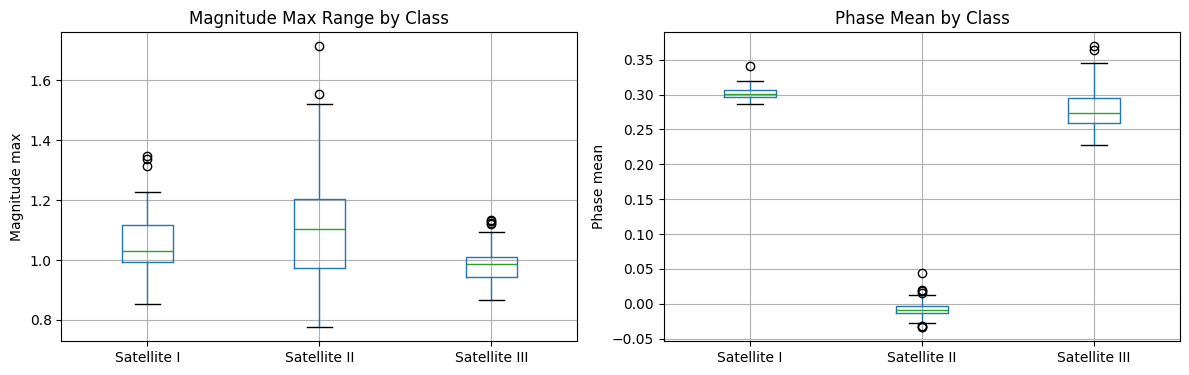

In [12]:
def parse_angles_from_name(path: Path) -> Tuple[int | None, int | None]:
    parts = path.stem.split("_")
    acc_angle, sta_angle = None, None
    for idx, token in enumerate(parts):
        if token == "AccAngle" and idx + 1 < len(parts):
            acc_angle = int(parts[idx + 1])
        if token == "StaAngle" and idx + 1 < len(parts):
            sta_angle = int(parts[idx + 1])
    return acc_angle, sta_angle


range_rows = []
for idx, path in enumerate(sample_paths, start=1):
    channels, label = load_tfpsstd_sample(path)
    mag = np.abs(channels).astype(np.float32)
    phase = np.angle(channels).astype(np.float32)
    acc_angle, sta_angle = parse_angles_from_name(path)
    range_rows.append(
        {
            "path": str(path),
            "label": label,
            "acc_angle": acc_angle,
            "sta_angle": sta_angle,
            "mag_min": float(np.min(mag)),
            "mag_max": float(np.max(mag)),
            "mag_mean": float(np.mean(mag)),
            "phase_min": float(np.min(phase)),
            "phase_max": float(np.max(phase)),
            "phase_mean": float(np.mean(phase)),
        }
    )
    del channels, mag, phase
    if idx % 50 == 0:
        gc.collect()
        print(f"range checked {idx}/{len(sample_paths)} files")

range_df = pd.DataFrame(range_rows)
display(range_df.groupby("label").agg({"path": "count", "mag_min": "min", "mag_max": "max", "phase_min": "min", "phase_max": "max"}))
display(pd.crosstab(range_df["label"], range_df["acc_angle"]))

DRIVE_OUT = Path("/content/drive/MyDrive/drdo/tfpsstd_outputs")
DRIVE_OUT.mkdir(parents=True, exist_ok=True)
range_df.to_csv(DRIVE_OUT / "dataset_range_summary.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
range_df.boxplot(column="mag_max", by="label", ax=axes[0])
axes[0].set_title("Magnitude Max Range by Class")
axes[0].set_xlabel("")
axes[0].set_ylabel("Magnitude max")
range_df.boxplot(column="phase_mean", by="label", ax=axes[1])
axes[1].set_title("Phase Mean by Class")
axes[1].set_xlabel("")
axes[1].set_ylabel("Phase mean")
fig.suptitle("")
fig.tight_layout()
fig.savefig(DRIVE_OUT / "magnitude_phase_range_plots.png", dpi=160)
plt.show()


## Feature Extraction for New Dataset

RAM-safe mode:

- Loads one `.mat` file at a time.
- Uses only `ISAR_FullPol_DualADMM`.
- Converts `complex128` to `complex64`.
- Converts `(H,W,4)` to `(4,H,W)`.
- Downsamples before creating magnitude/phase vectors.
- Saves compact NumPy matrices to Drive.


In [13]:
def resize_channels(x: np.ndarray, size: int = 64) -> np.ndarray:
    tensor = torch.from_numpy(np.asarray(x).real.astype(np.float32)).unsqueeze(0)
    return F.interpolate(tensor, size=(size, size), mode="bilinear", align_corners=False).squeeze(0).numpy()


def generic_mag_phase_vector(channels: np.ndarray, feature_size: int = FEATURE_SIZE) -> np.ndarray:
    if np.iscomplexobj(channels):
        mag = np.abs(channels).astype(np.float32)
        phase = (np.angle(channels) / np.pi).astype(np.float32)
        mag_small = resize_channels(mag, feature_size)
        phase_small = resize_channels(phase, feature_size)
        return np.concatenate([mag_small.reshape(-1), phase_small.reshape(-1)]).astype(np.float32)
    mag_small = resize_channels(channels.astype(np.float32), feature_size)
    return mag_small.reshape(-1).astype(np.float32)


def generic_rcs_vector(channels: np.ndarray) -> np.ndarray:
    power = np.abs(channels) ** 2
    features = []
    for idx in range(power.shape[0]):
        p = power[idx].reshape(-1)
        features.extend([p.sum(), p.mean(), p.max(), p.std(), 10 * np.log10(max(p.sum(), 1e-12))])
    allp = power.reshape(-1)
    features.extend([allp.sum(), allp.mean(), allp.max(), 10 * np.log10(max(allp.sum(), 1e-12))])
    return np.asarray(features, dtype=np.float32)


X_rows, R_rows, labels, paths_used = [], [], [], []
for idx, path in enumerate(sample_paths, start=1):
    try:
        channels, label = load_tfpsstd_sample(path)
        X_rows.append(generic_mag_phase_vector(channels, feature_size=FEATURE_SIZE))
        R_rows.append(generic_rcs_vector(channels))
        labels.append(label)
        paths_used.append(str(path))
        del channels
        if idx % 25 == 0:
            gc.collect()
            print(f"processed {idx}/{len(sample_paths)} files")
    except Exception as exc:
        print("Skipping:", path, exc)

assert X_rows, "No usable samples parsed yet. Adjust load_tfpsstd_sample after inspecting the format."

X = np.stack(X_rows).astype(np.float32)
R = np.stack(R_rows).astype(np.float32)
label_names = sorted(set(labels))
label_to_id = {name: idx for idx, name in enumerate(label_names)}
y = np.array([label_to_id[label] for label in labels], dtype=np.int64)

print("Feature matrix:", X.shape)
print("RCS matrix:", R.shape)
print("Labels:", label_to_id)
print("Feature size used:", FEATURE_SIZE, "x", FEATURE_SIZE)

OUT = Path("/content/tfpsstd_outputs")
OUT.mkdir(exist_ok=True)
DRIVE_OUT = Path("/content/drive/MyDrive/drdo/tfpsstd_outputs")
DRIVE_OUT.mkdir(parents=True, exist_ok=True)
np.save(OUT / "X_mag_phase.npy", X)
np.save(OUT / "X_rcs.npy", R)
np.save(OUT / "y.npy", y)
(OUT / "labels.json").write_text(json.dumps(label_to_id, indent=2))
(OUT / "paths.json").write_text(json.dumps(paths_used, indent=2))
for fname in ["X_mag_phase.npy", "X_rcs.npy", "y.npy", "labels.json", "paths.json"]:
    shutil.copy2(OUT / fname, DRIVE_OUT / fname)
print("Saved feature matrices to:", OUT)
print("Copied feature matrices to Drive:", DRIVE_OUT)


processed 25/393 files
processed 50/393 files
processed 75/393 files
processed 100/393 files
processed 125/393 files
processed 150/393 files
processed 175/393 files
processed 200/393 files
processed 225/393 files
processed 250/393 files
processed 275/393 files
processed 300/393 files
processed 325/393 files
processed 350/393 files
processed 375/393 files
Feature matrix: (393, 8192)
RCS matrix: (393, 24)
Labels: {'Satellite I': 0, 'Satellite II': 1, 'Satellite III': 2}
Feature size used: 32 x 32
Saved feature matrices to: /content/tfpsstd_outputs
Copied feature matrices to Drive: /content/drive/MyDrive/drdo/tfpsstd_outputs


## Classification Split Setup

For the main classification report, use a view-disjoint split. Files with the
same `(AccAngle, StaAngle)` are kept together in either train or test. This is
stricter than a plain random split and reduces the chance that nearly identical
aspect-angle samples appear in both train and test.


In [14]:
split_rows = []
for path_str, label_id in zip(paths_used, y):
    path = Path(path_str)
    acc_angle, sta_angle = parse_angles_from_name(path)
    split_rows.append(
        {
            "path": path_str,
            "label_id": int(label_id),
            "label": label_names[int(label_id)],
            "acc_angle": acc_angle,
            "sta_angle": sta_angle,
            "view_group": f"acc{acc_angle}_sta{sta_angle}",
        }
    )

split_df = pd.DataFrame(split_rows)
groups = split_df["view_group"].to_numpy()

if split_df["view_group"].nunique() >= 5:
    splitter = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)
    train_idx, test_idx = next(splitter.split(X, y, groups=groups))
    SPLIT_PROTOCOL = "view_disjoint_group_split_by_accangle_staangle"
else:
    train_idx, test_idx = train_test_split(np.arange(len(y)), test_size=0.25, random_state=42, stratify=y)
    SPLIT_PROTOCOL = "stratified_random_split"

print("Split protocol:", SPLIT_PROTOCOL)
print("Train/Test:", len(train_idx), len(test_idx))
train_paths = [paths_used[i] for i in train_idx]
test_paths = [paths_used[i] for i in test_idx]
train_y = y[train_idx]
test_y = y[test_idx]
display(pd.crosstab(split_df.iloc[train_idx]["label"], split_df.iloc[train_idx]["acc_angle"]))
display(pd.crosstab(split_df.iloc[test_idx]["label"], split_df.iloc[test_idx]["acc_angle"]))
split_df.to_csv(DRIVE_OUT / "classification_split_metadata.csv", index=False)
(DRIVE_OUT / "classification_split_indices.json").write_text(
    json.dumps({"protocol": SPLIT_PROTOCOL, "train_idx": train_idx.tolist(), "test_idx": test_idx.tolist()}, indent=2)
)


Split protocol: view_disjoint_group_split_by_accangle_staangle
Train/Test: 294 99


acc_angle,8,16,32
label,,,
Satellite I,37,31,30
Satellite II,37,31,30
Satellite III,37,31,30


acc_angle,8,16,32
label,,,
Satellite I,8,13,12
Satellite II,8,13,12
Satellite III,8,13,12


3534

## Feature-Based Classification, Train-Only Normalization, Feature Selection

This section performs actual target classification using compact magnitude +
phase features. Normalization statistics are computed only from the training
split and applied unchanged to the test split.


{
  "split_protocol": "view_disjoint_group_split_by_accangle_staangle",
  "feature_input": "magnitude_phase_concat",
  "normalization": "raw",
  "classifier": "SGD_logistic",
  "test_accuracy": 0.7272727272727273,
  "test_f1_macro": 0.7262689001819437,
  "confusion_matrix": [
    [
      22,
      0,
      11
    ],
    [
      0,
      32,
      1
    ],
    [
      14,
      1,
      18
    ]
  ]
}
{
  "split_protocol": "view_disjoint_group_split_by_accangle_staangle",
  "feature_input": "magnitude_phase_concat",
  "normalization": "raw",
  "classifier": "Linear_SVM",
  "test_accuracy": 0.7474747474747475,
  "test_f1_macro": 0.7469519208649643,
  "confusion_matrix": [
    [
      22,
      0,
      11
    ],
    [
      0,
      33,
      0
    ],
    [
      14,
      0,
      19
    ]
  ]
}
{
  "split_protocol": "view_disjoint_group_split_by_accangle_staangle",
  "feature_input": "magnitude_phase_concat",
  "normalization": "raw",
  "classifier": "Random_Forest",
  "test_accuracy":

/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


{
  "split_protocol": "view_disjoint_group_split_by_accangle_staangle",
  "feature_input": "magnitude_phase_concat",
  "normalization": "robust_iqr",
  "classifier": "Linear_SVM",
  "test_accuracy": 0.9191919191919192,
  "test_f1_macro": 0.9186481795177448,
  "confusion_matrix": [
    [
      29,
      1,
      3
    ],
    [
      4,
      29,
      0
    ],
    [
      0,
      0,
      33
    ]
  ]
}
{
  "split_protocol": "view_disjoint_group_split_by_accangle_staangle",
  "feature_input": "magnitude_phase_concat",
  "normalization": "robust_iqr",
  "classifier": "Random_Forest",
  "test_accuracy": 1.0,
  "test_f1_macro": 1.0,
  "confusion_matrix": [
    [
      33,
      0,
      0
    ],
    [
      0,
      33,
      0
    ],
    [
      0,
      0,
      33
    ]
  ]
}
{
  "split_protocol": "view_disjoint_group_split_by_accangle_staangle",
  "feature_input": "magnitude_phase_concat",
  "normalization": "maxabs",
  "classifier": "SGD_logistic",
  "test_accuracy": 0.89898989898989

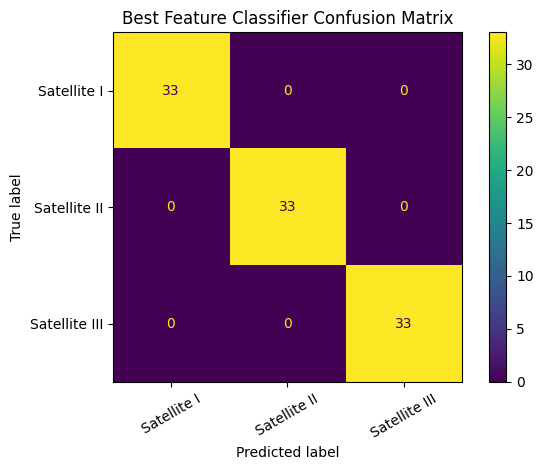

/usr/local/lib/python3.12/dist-packages/sklearn/feature_selection/_univariate_selection.py:111: UserWarning: Features [4096 4097 4098 ... 5117 5118 5119] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/usr/local/lib/python3.12/dist-packages/sklearn/feature_selection/_univariate_selection.py:112: RuntimeWarning: invalid value encountered in divide
  f = msb / msw


Feature selection: {'method': 'anova_f', 'num_features': 512, 'top_index': 103, 'top_score': 67.91506958007812, 'mean_score': 69.13152313232422}
Selected-feature result: {
  "selector": "ANOVA-F",
  "selected_features": 512,
  "test_accuracy": 0.7878787878787878,
  "test_f1_macro": 0.7746913580246914,
  "confusion_matrix": [
    [
      17,
      11,
      5
    ],
    [
      4,
      28,
      1
    ],
    [
      0,
      0,
      33
    ]
  ]
}


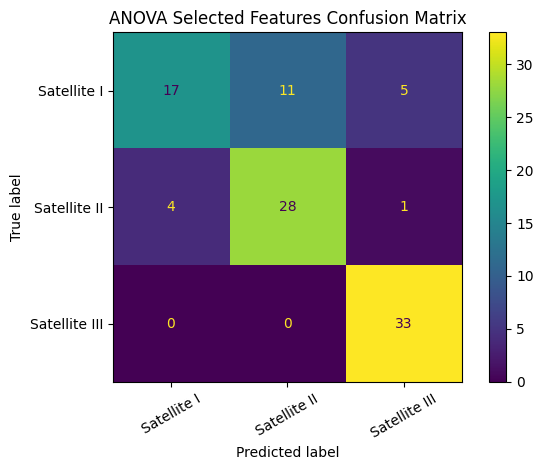

In [15]:
if len(label_names) < 2:
    print("Only one class found. Download Satellite I, II, and III for classification.")
else:
    X_train, X_test, y_train, y_test = X[train_idx], X[test_idx], y[train_idx], y[test_idx]
    stats = compute_column_stats(X_train)
    methods = ["raw", "standard_z", "minmax_-1_1", "robust_iqr", "maxabs"]
    classifiers = {
        "SGD_logistic": lambda: SGDClassifier(loss="log_loss", alpha=1e-4, max_iter=2000, tol=1e-4, random_state=42),
        "Linear_SVM": lambda: LinearSVC(C=1.0, random_state=42, max_iter=5000),
        "Random_Forest": lambda: RandomForestClassifier(n_estimators=300, random_state=42, class_weight="balanced", n_jobs=-1),
    }
    rows = []
    for method in methods:
        Xtr = normalize_with_train_stats(X_train, stats, method)
        Xte = normalize_with_train_stats(X_test, stats, method)
        for clf_name, make_clf in classifiers.items():
            clf = make_clf()
            clf.fit(Xtr, y_train)
            pred = clf.predict(Xte)
            cm = confusion_matrix(y_test, pred, labels=list(range(len(label_names))))
            row = {
                "split_protocol": SPLIT_PROTOCOL,
                "feature_input": "magnitude_phase_concat",
                "normalization": method,
                "classifier": clf_name,
                "test_accuracy": float(accuracy_score(y_test, pred)),
                "test_f1_macro": float(f1_score(y_test, pred, average="macro")),
                "confusion_matrix": cm.tolist(),
            }
            rows.append(row)
            print(json.dumps(row, indent=2))
    (OUT / "normalization_results.json").write_text(json.dumps(rows, indent=2))
    (DRIVE_OUT / "normalization_results.json").write_text(json.dumps(rows, indent=2))
    pd.DataFrame([{k: v for k, v in row.items() if k != "confusion_matrix"} for row in rows]).to_csv(
        DRIVE_OUT / "normalization_results.csv", index=False
    )

    best_row = max(rows, key=lambda row: (row["test_f1_macro"], row["test_accuracy"]))
    print("Best feature classifier:", json.dumps(best_row, indent=2))
    (DRIVE_OUT / "best_feature_classifier_result.json").write_text(json.dumps(best_row, indent=2))

    best_cm = np.array(best_row["confusion_matrix"])
    disp = ConfusionMatrixDisplay(best_cm, display_labels=label_names)
    disp.plot(values_format="d", xticks_rotation=30)
    plt.title("Best Feature Classifier Confusion Matrix")
    plt.tight_layout()
    plt.savefig(DRIVE_OUT / "best_feature_classifier_confusion_matrix.png", dpi=160)
    plt.show()

    Xtr_z = normalize_with_train_stats(X_train, stats, "standard_z")
    Xte_z = normalize_with_train_stats(X_test, stats, "standard_z")
    selection = select_anova_f(Xtr_z, y_train, k=min(512, Xtr_z.shape[1]))
    print("Feature selection:", summarize_selection(selection))
    Xtr_sel = apply_selection(Xtr_z, selection.indices)
    Xte_sel = apply_selection(Xte_z, selection.indices)
    clf = SGDClassifier(loss="log_loss", alpha=1e-4, max_iter=2000, tol=1e-4, random_state=42)
    clf.fit(Xtr_sel, y_train)
    pred = clf.predict(Xte_sel)
    selected_cm = confusion_matrix(y_test, pred, labels=list(range(len(label_names))))
    selected_result = {
        "selector": "ANOVA-F",
        "selected_features": int(len(selection.indices)),
        "test_accuracy": float(accuracy_score(y_test, pred)),
        "test_f1_macro": float(f1_score(y_test, pred, average="macro")),
        "confusion_matrix": selected_cm.tolist(),
    }
    print("Selected-feature result:", json.dumps(selected_result, indent=2))
    (DRIVE_OUT / "feature_selection_result.json").write_text(json.dumps(selected_result, indent=2))

    disp = ConfusionMatrixDisplay(selected_cm, display_labels=label_names)
    disp.plot(values_format="d", xticks_rotation=30)
    plt.title("ANOVA Selected Features Confusion Matrix")
    plt.tight_layout()
    plt.savefig(DRIVE_OUT / "feature_selection_confusion_matrix.png", dpi=160)
    plt.show()


## Scratch ResNet18 Magnitude Baseline

Train from scratch. Do not load Pol-ISAR weights.


epoch 1 [20/74] loss=1.1145
epoch 1 [40/74] loss=1.0336
epoch 1 [60/74] loss=0.8968
epoch 1 [74/74] loss=0.8363
epoch 1 train_loss 0.8363373336961141 lr 0.0003
epoch 2 [20/74] loss=0.3632
epoch 2 [40/74] loss=0.4026
epoch 2 [60/74] loss=0.4213
epoch 2 [74/74] loss=0.3827
epoch 2 train_loss 0.38266656265870946 lr 0.0003
epoch 3 [20/74] loss=0.3401
epoch 3 [40/74] loss=0.3127
epoch 3 [60/74] loss=0.3417
epoch 3 [74/74] loss=0.3216
epoch 3 train_loss 0.321575795275134 lr 0.0003
epoch 4 [20/74] loss=0.4589
epoch 4 [40/74] loss=0.3573
epoch 4 [60/74] loss=0.3011
epoch 4 [74/74] loss=0.3085
epoch 4 train_loss 0.30851280703083483 lr 0.0003
epoch 5 [20/74] loss=0.0982
epoch 5 [40/74] loss=0.1758
epoch 5 [60/74] loss=0.1552
epoch 5 [74/74] loss=0.1423
epoch 5 train_loss 0.14229854089333802 lr 0.0003
Scratch ResNet18 result: {
  "model": "ResNet18 magnitude-only from scratch",
  "split_protocol": "view_disjoint_group_split_by_accangle_staangle",
  "image_size": 128,
  "batch_size": 4,
  "test_ac

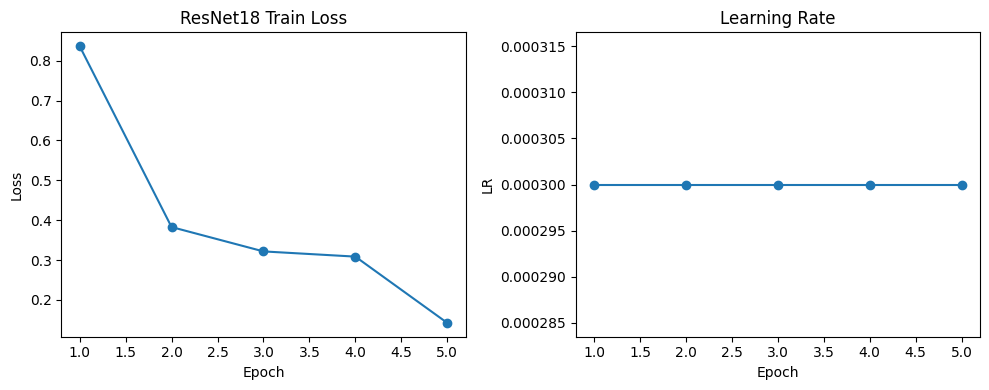

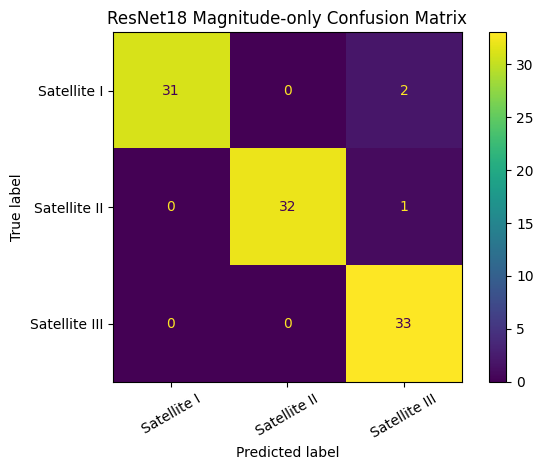

In [16]:
class GenericMagnitudeDataset(Dataset):
    def __init__(self, paths: Sequence[str], labels: Sequence[int], size: int = CNN_IMAGE_SIZE) -> None:
        self.paths = [Path(p) for p in paths]
        self.labels = list(labels)
        self.size = size

    def __len__(self) -> int:
        return len(self.paths)

    def __getitem__(self, idx: int):
        channels, _ = load_tfpsstd_sample(self.paths[idx])
        mag = np.abs(channels).astype(np.float32)
        if mag.shape[0] == 1:
            mag = np.repeat(mag, 3, axis=0)
        elif mag.shape[0] == 2:
            mag = np.concatenate([mag, mag[:1]], axis=0)
        elif mag.shape[0] >= 3:
            mag = mag[:3]
        tensor = torch.from_numpy(mag).float().unsqueeze(0)
        tensor = F.interpolate(tensor, size=(self.size, self.size), mode="bilinear", align_corners=False).squeeze(0)
        # Per-image scaling is avoided for final work; this is only a scratch baseline.
        return tensor, torch.tensor(self.labels[idx], dtype=torch.long)


if len(label_names) < 2:
    print("Skipping ResNet18: need at least two classes.")
else:
    train_ds = GenericMagnitudeDataset(train_paths, train_y, size=CNN_IMAGE_SIZE)
    test_ds = GenericMagnitudeDataset(test_paths, test_y, size=CNN_IMAGE_SIZE)
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=torch.cuda.is_available())
    test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=torch.cuda.is_available())
    model = resnet18(weights=None)
    model.fc = nn.Linear(model.fc.in_features, len(label_names))
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=3e-4)
    criterion = nn.CrossEntropyLoss()
    history = []
    for epoch in range(5):
        model.train()
        total = 0.0
        for step, (xb, yb) in enumerate(train_loader, start=1):
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            loss = criterion(logits, yb)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            total += float(loss.detach().cpu())
            if step % 20 == 0 or step == len(train_loader):
                print(f"epoch {epoch + 1} [{step}/{len(train_loader)}] loss={total / step:.4f}")
        epoch_loss = total / max(len(train_loader), 1)
        current_lr = opt.param_groups[0]["lr"]
        history.append({"epoch": epoch + 1, "train_loss": float(epoch_loss), "lr": float(current_lr)})
        print("epoch", epoch + 1, "train_loss", epoch_loss, "lr", current_lr)
        gc.collect()
    model.eval()
    preds, targets = [], []
    with torch.no_grad():
        for xb, yb in test_loader:
            logits = model(xb.to(device))
            preds.extend(logits.argmax(dim=1).cpu().tolist())
            targets.extend(yb.tolist())
    resnet_cm = confusion_matrix(targets, preds, labels=list(range(len(label_names))))
    resnet_result = {
        "model": "ResNet18 magnitude-only from scratch",
        "split_protocol": SPLIT_PROTOCOL,
        "image_size": CNN_IMAGE_SIZE,
        "batch_size": BATCH_SIZE,
        "test_accuracy": float(accuracy_score(targets, preds)),
        "test_f1_macro": float(f1_score(targets, preds, average="macro")),
        "confusion_matrix": resnet_cm.tolist(),
    }
    print("Scratch ResNet18 result:", json.dumps(resnet_result, indent=2))
    (DRIVE_OUT / "resnet18_magnitude_result.json").write_text(json.dumps(resnet_result, indent=2))
    pd.DataFrame(history).to_csv(DRIVE_OUT / "resnet18_training_history.csv", index=False)

    hist_df = pd.DataFrame(history)
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].plot(hist_df["epoch"], hist_df["train_loss"], marker="o")
    axes[0].set_title("ResNet18 Train Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[1].plot(hist_df["epoch"], hist_df["lr"], marker="o")
    axes[1].set_title("Learning Rate")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("LR")
    fig.tight_layout()
    fig.savefig(DRIVE_OUT / "resnet18_loss_lr_curves.png", dpi=160)
    plt.show()

    disp = ConfusionMatrixDisplay(resnet_cm, display_labels=label_names)
    disp.plot(values_format="d", xticks_rotation=30)
    plt.title("ResNet18 Magnitude-only Confusion Matrix")
    plt.tight_layout()
    plt.savefig(DRIVE_OUT / "resnet18_confusion_matrix.png", dpi=160)
    plt.show()


## Complex CNN Classification Baseline

This model is intentionally simple and trained from scratch. It keeps complex
information by feeding real and imaginary parts as separate channels:
4 polarimetric complex channels -> 8 real-valued channels.


Small complex-input CNN real+imag channels epoch 1 [20/74] loss=1.0639 acc=0.412
Small complex-input CNN real+imag channels epoch 1 [40/74] loss=1.0446 acc=0.519
Small complex-input CNN real+imag channels epoch 1 [60/74] loss=1.0259 acc=0.592
Small complex-input CNN real+imag channels epoch 1 [74/74] loss=0.9987 acc=0.616
Small complex-input CNN real+imag channels epoch 2 [20/74] loss=0.7575 acc=0.787
Small complex-input CNN real+imag channels epoch 2 [40/74] loss=0.6745 acc=0.838
Small complex-input CNN real+imag channels epoch 2 [60/74] loss=0.5982 acc=0.871
Small complex-input CNN real+imag channels epoch 2 [74/74] loss=0.5589 acc=0.881
Small complex-input CNN real+imag channels epoch 3 [20/74] loss=0.3718 acc=0.875
Small complex-input CNN real+imag channels epoch 3 [40/74] loss=0.3324 acc=0.912
Small complex-input CNN real+imag channels epoch 3 [60/74] loss=0.3444 acc=0.900
Small complex-input CNN real+imag channels epoch 3 [74/74] loss=0.3422 acc=0.901
Small complex-input CNN real

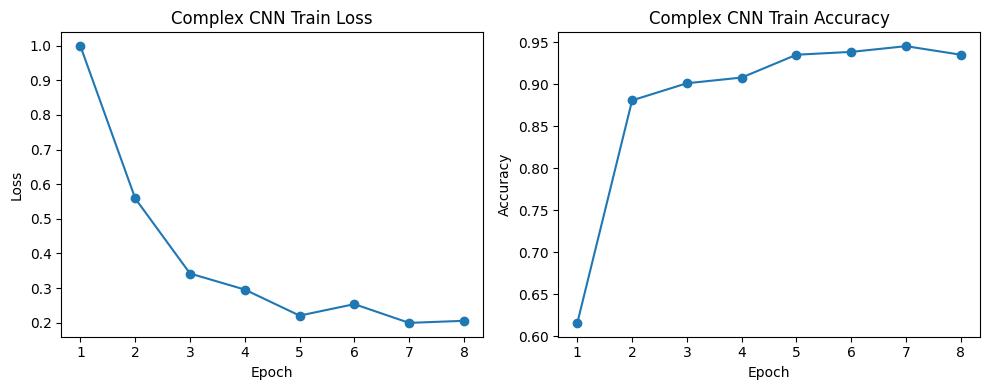

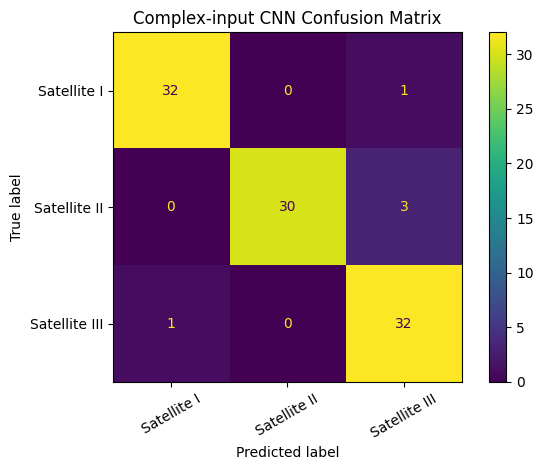

,model,split_protocol,test_accuracy,test_f1_macro
0,Random_Forest,view_disjoint_group_split_by_accangle_staangle,1.000000,1.000000
1,ResNet18 magnitude-only from scratch,view_disjoint_group_split_by_accangle_staangle,0.969697,0.969962
2,Small complex-input CNN real+imag channels,view_disjoint_group_split_by_accangle_staangle,0.949495,0.949871


In [17]:
class TFPSSTDComplexTensorDataset(Dataset):
    def __init__(self, paths: Sequence[str], labels: Sequence[int], size: int = CNN_IMAGE_SIZE) -> None:
        self.paths = [Path(p) for p in paths]
        self.labels = list(labels)
        self.size = size

    def __len__(self) -> int:
        return len(self.paths)

    def __getitem__(self, idx: int):
        channels, _ = load_tfpsstd_sample(self.paths[idx])
        if not np.iscomplexobj(channels):
            real = channels.astype(np.float32)
            imag = np.zeros_like(real, dtype=np.float32)
        else:
            real = channels.real.astype(np.float32)
            imag = channels.imag.astype(np.float32)
        stacked = np.concatenate([real, imag], axis=0)
        tensor = torch.from_numpy(stacked).float().unsqueeze(0)
        tensor = F.interpolate(tensor, size=(self.size, self.size), mode="bilinear", align_corners=False).squeeze(0)
        return tensor, torch.tensor(self.labels[idx], dtype=torch.long)


class SmallComplexInputCNN(nn.Module):
    def __init__(self, in_channels: int, num_classes: int) -> None:
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_channels, 32, kernel_size=5, stride=2, padding=2, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 128, kernel_size=3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Linear(128, num_classes),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)


def train_image_classifier(model: nn.Module, train_loader: DataLoader, test_loader: DataLoader, name: str, epochs: int = 8):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=3e-4)
    criterion = nn.CrossEntropyLoss()
    history = []
    for epoch in range(epochs):
        model.train()
        total = 0.0
        correct = 0
        seen = 0
        for step, (xb, yb) in enumerate(train_loader, start=1):
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            loss = criterion(logits, yb)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            total += float(loss.detach().cpu())
            correct += int((logits.argmax(dim=1) == yb).sum().detach().cpu())
            seen += int(yb.numel())
            if step % 20 == 0 or step == len(train_loader):
                print(f"{name} epoch {epoch + 1} [{step}/{len(train_loader)}] loss={total / step:.4f} acc={correct / max(seen, 1):.3f}")
        history.append(
            {
                "epoch": epoch + 1,
                "train_loss": float(total / max(len(train_loader), 1)),
                "train_accuracy": float(correct / max(seen, 1)),
                "lr": float(opt.param_groups[0]["lr"]),
            }
        )
        gc.collect()

    model.eval()
    preds, targets = [], []
    with torch.no_grad():
        for xb, yb in test_loader:
            logits = model(xb.to(device))
            preds.extend(logits.argmax(dim=1).cpu().tolist())
            targets.extend(yb.tolist())

    cm = confusion_matrix(targets, preds, labels=list(range(len(label_names))))
    result = {
        "model": name,
        "split_protocol": SPLIT_PROTOCOL,
        "image_size": CNN_IMAGE_SIZE,
        "batch_size": BATCH_SIZE,
        "epochs": epochs,
        "test_accuracy": float(accuracy_score(targets, preds)),
        "test_f1_macro": float(f1_score(targets, preds, average="macro")),
        "confusion_matrix": cm.tolist(),
    }
    return result, pd.DataFrame(history), cm


if len(label_names) < 2:
    print("Skipping complex CNN: need at least two classes.")
else:
    complex_train_ds = TFPSSTDComplexTensorDataset(train_paths, train_y, size=CNN_IMAGE_SIZE)
    complex_test_ds = TFPSSTDComplexTensorDataset(test_paths, test_y, size=CNN_IMAGE_SIZE)
    complex_train_loader = DataLoader(complex_train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=torch.cuda.is_available())
    complex_test_loader = DataLoader(complex_test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=torch.cuda.is_available())
    complex_model = SmallComplexInputCNN(in_channels=8, num_classes=len(label_names))
    complex_result, complex_history, complex_cm = train_image_classifier(
        complex_model,
        complex_train_loader,
        complex_test_loader,
        name="Small complex-input CNN real+imag channels",
        epochs=8,
    )
    print("Complex CNN result:", json.dumps(complex_result, indent=2))
    (DRIVE_OUT / "complex_input_cnn_result.json").write_text(json.dumps(complex_result, indent=2))
    complex_history.to_csv(DRIVE_OUT / "complex_input_cnn_training_history.csv", index=False)

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].plot(complex_history["epoch"], complex_history["train_loss"], marker="o")
    axes[0].set_title("Complex CNN Train Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[1].plot(complex_history["epoch"], complex_history["train_accuracy"], marker="o")
    axes[1].set_title("Complex CNN Train Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy")
    fig.tight_layout()
    fig.savefig(DRIVE_OUT / "complex_input_cnn_training_curves.png", dpi=160)
    plt.show()

    disp = ConfusionMatrixDisplay(complex_cm, display_labels=label_names)
    disp.plot(values_format="d", xticks_rotation=30)
    plt.title("Complex-input CNN Confusion Matrix")
    plt.tight_layout()
    plt.savefig(DRIVE_OUT / "complex_input_cnn_confusion_matrix.png", dpi=160)
    plt.show()

    comparison_rows = []
    for file_name in ["best_feature_classifier_result.json", "resnet18_magnitude_result.json", "complex_input_cnn_result.json"]:
        path = DRIVE_OUT / file_name
        if path.exists():
            comparison_rows.append(json.loads(path.read_text()))
    comparison_df = pd.DataFrame(
        [
            {
                "model": row.get("model", row.get("classifier", row.get("feature_input", "feature_classifier"))),
                "split_protocol": row.get("split_protocol", SPLIT_PROTOCOL),
                "test_accuracy": row.get("test_accuracy"),
                "test_f1_macro": row.get("test_f1_macro"),
            }
            for row in comparison_rows
        ]
    )
    display(comparison_df)
    comparison_df.to_csv(DRIVE_OUT / "classification_model_comparison.csv", index=False)


In [ ]:
2,.0